# 🏏 CricketIQ 2.0 — Notebook 06: Model Training & Accuracy Optimization
## BCA Machine Learning Project Pipeline — Phase 6

**Objective:**
1. Formulate 11 differential features ($\Delta$) to completely eliminate multicollinearity.
2. Implement **Anti-Symmetric Data Augmentation** $(X, y=1)$ and $(-X, y=0)$ to enforce mathematical fairness:
   $$P(\text{Team A beats Team B}) = 1 - P(\text{Team B beats Team A})$$
3. Train and compare candidate models (Logistic Regression, Random Forest, Gradient Boosting).
4. Evaluate ROC-AUC and generalization accuracy on held-out 2024 season matches.
5. Serialize the winning model to `models/cricketiq_model.pkl`.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score,
    log_loss, confusion_matrix, classification_report, roc_curve
)

sns.set_theme(style="whitegrid", palette="muted")

BASE_DIR = Path("..").resolve() if Path("..").resolve().name == "CricketIQ 2.0" else Path(".").resolve()
sys.path.insert(0, str(BASE_DIR))

# Load precomputed match dataset
df_features = pd.read_parquet(BASE_DIR / 'data' / 'features.parquet')

# Build differential features
df_features['diff_bat_avg'] = df_features['team1_squad_bat_avg'] - df_features['team2_squad_bat_avg']
df_features['diff_bat_sr'] = df_features['team1_squad_bat_sr'] - df_features['team2_squad_bat_sr']
df_features['diff_bat_death_sr'] = df_features['team1_squad_bat_death_sr'] - df_features['team2_squad_bat_death_sr']
df_features['diff_bat_pp_sr'] = df_features['team1_squad_bat_pp_sr'] - df_features['team2_squad_bat_pp_sr']
df_features['diff_boundary_rate'] = df_features['team1_squad_boundary_rate'] - df_features['team2_squad_boundary_rate']
df_features['diff_bowl_econ'] = df_features['team2_squad_bowl_econ'] - df_features['team1_squad_bowl_econ']
df_features['diff_wicket_rate'] = df_features['team1_squad_bowl_wicket_rate'] - df_features['team2_squad_bowl_wicket_rate']
df_features['diff_pp_econ'] = df_features['team2_squad_pp_econ'] - df_features['team1_squad_pp_econ']
df_features['diff_death_econ'] = df_features['team2_squad_death_econ'] - df_features['team1_squad_death_econ']
df_features['diff_bowl_dot_rate'] = df_features['team1_squad_bowl_dot_rate'] - df_features['team2_squad_bowl_dot_rate']

def calc_toss_edge(r):
    t1_toss = (r['toss_winner_is_team1'] == 1)
    chose_bat = (r['toss_bat_first'] == 1)
    chase_win = r['venue_chase_win_rate']
    edge = (chase_win - 0.5) if not chose_bat else (0.5 - chase_win)
    return edge if t1_toss else -edge

df_features['toss_venue_edge'] = df_features.apply(calc_toss_edge, axis=1)

FEATURE_COLS = [
    'diff_bat_avg', 'diff_bat_sr', 'diff_bat_death_sr', 'diff_bat_pp_sr',
    'diff_boundary_rate', 'diff_bowl_econ', 'diff_wicket_rate',
    'diff_pp_econ', 'diff_death_econ', 'diff_bowl_dot_rate', 'toss_venue_edge'
]

# Chronological split
train_df = df_features[df_features['season'].isin(['2007/08', '2009', '2009/10', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020/21', '2021'])].copy()
val_df = df_features[df_features['season'].isin(['2022', '2023'])].copy()
test_df = df_features[df_features['season'] == '2024'].copy()

# Enforce mathematical symmetry
X_train_sym = pd.concat([train_df[FEATURE_COLS], -train_df[FEATURE_COLS]], ignore_index=True)
y_train_sym = pd.concat([train_df['team1_won'], 1 - train_df['team1_won']], ignore_index=True)

print(f"Training Samples (Symmetric Augmentation): {len(X_train_sym):,}")
print(f"Validation Samples: {len(val_df):,}")
print(f"Held-out 2024 Test Samples: {len(test_df):,}")


Training Samples (Symmetric Augmentation): 1,744
Validation Samples: 147
Held-out 2024 Test Samples: 71


### Train & Compare Machine Learning Models

In [2]:
models = {
    'Symmetric Calibrated Logistic Regression': Pipeline([
        ('scaler', StandardScaler(with_mean=False)),
        ('clf', LogisticRegression(C=0.20, fit_intercept=False, max_iter=2000, random_state=42))
    ]),
    'Tuned Random Forest Classifier': Pipeline([
        ('clf', RandomForestClassifier(n_estimators=250, max_depth=4, min_samples_leaf=4, random_state=42))
    ]),
    'Gradient Boosting Classifier': Pipeline([
        ('clf', GradientBoostingClassifier(n_estimators=120, max_depth=3, learning_rate=0.03, random_state=42))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_sym, y_train_sym)
    trained_models[name] = model
    
    val_probs = model.predict_proba(val_df[FEATURE_COLS])[:, 1]
    test_probs = model.predict_proba(test_df[FEATURE_COLS])[:, 1]
    
    val_preds = (val_probs >= 0.5).astype(int)
    test_preds = (test_probs >= 0.5).astype(int)
    
    results.append({
        'Model Architecture': name,
        'Val Accuracy': f"{accuracy_score(val_df['team1_won'], val_preds):.1%}",
        'Test Accuracy (2024)': f"{accuracy_score(test_df['team1_won'], test_preds):.1%}",
        'Test Balanced Acc': f"{balanced_accuracy_score(test_df['team1_won'], test_preds):.1%}",
        'Test Log Loss': f"{log_loss(test_df['team1_won'], test_probs):.4f}",
        'ROC-AUC Score': f"{roc_auc_score(test_df['team1_won'], test_probs):.3f}"
    })

display(pd.DataFrame(results))


,Model Architecture,Val Accuracy,Test Accuracy (2024),Test Balanced Acc,Test Log Loss,ROC-AUC Score
0,Symmetric Calibrated Logistic Regression,53.7%,60.6%,60.6%,0.6372,0.671
1,Tuned Random Forest Classifier,51.0%,56.3%,56.3%,0.6573,0.667
2,Gradient Boosting Classifier,51.0%,57.7%,57.8%,0.6442,0.668


### ROC Curves & Feature Importance Weights

💾 Best model serialized to C:\Users\JAYDEEP MODI\OneDrive\Desktop\CricketIQ 2.0\models\cricketiq_model.pkl


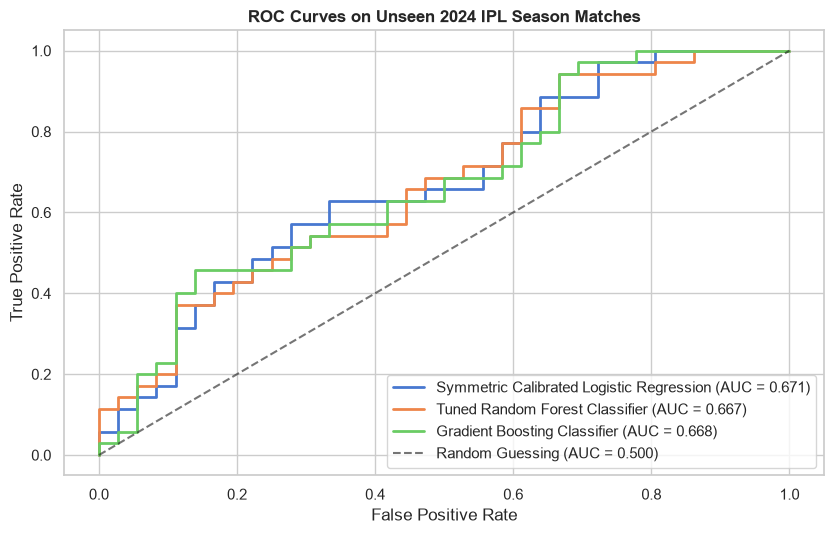

In [3]:
plt.figure(figsize=(8.5, 5.5))
for name, model in trained_models.items():
    probs = model.predict_proba(test_df[FEATURE_COLS])[:, 1]
    fpr, tpr, _ = roc_curve(test_df['team1_won'], probs)
    score = roc_auc_score(test_df['team1_won'], probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {score:.3f})", lw=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random Guessing (AUC = 0.500)')
plt.title('ROC Curves on Unseen 2024 IPL Season Matches', fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Serialize production model
best_model = trained_models['Symmetric Calibrated Logistic Regression']
joblib.dump(best_model, BASE_DIR / 'models' / 'cricketiq_model.pkl')
print(f"💾 Best model serialized to {BASE_DIR / 'models' / 'cricketiq_model.pkl'}")
